In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr,chi2_contingency
import warnings
warnings.filterwarnings('ignore')


In [74]:
heart = pd.read_csv('heart.csv')
heart.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [14]:
heart.shape

(918, 12)

In [16]:
heart.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

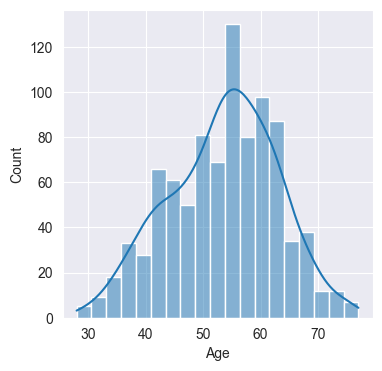

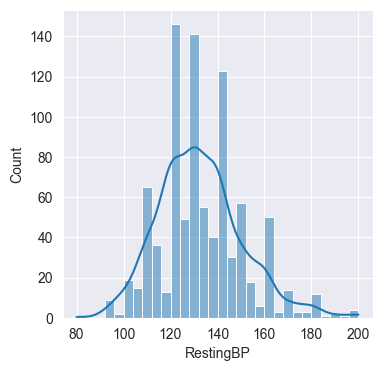

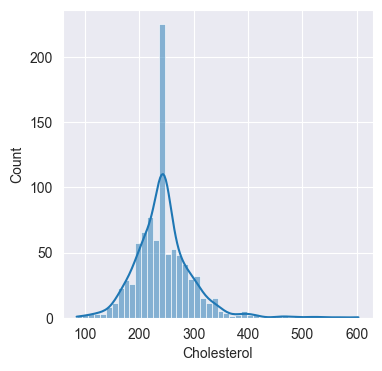

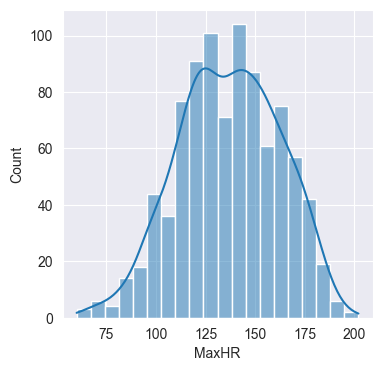

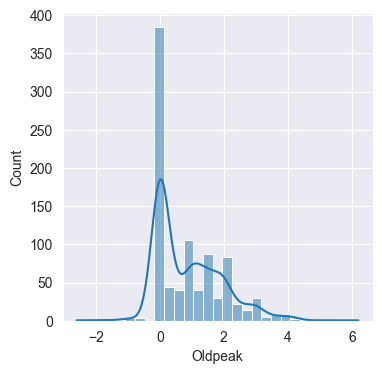

In [88]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
for col in num_cols:
    plt.figure(figsize = (4,4))
    sns.histplot(data=heart_df,x=col,kde=True)

In [30]:
cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

print(heart[cols].describe())

              Age   RestingBP  Cholesterol       MaxHR     Oldpeak
count  918.000000  918.000000   918.000000  918.000000  918.000000
mean    53.510893  132.396514   198.799564  136.809368    0.887364
std      9.432617   18.514154   109.384145   25.460334    1.066570
min     28.000000    0.000000     0.000000   60.000000   -2.600000
25%     47.000000  120.000000   173.250000  120.000000    0.000000
50%     54.000000  130.000000   223.000000  138.000000    0.600000
75%     60.000000  140.000000   267.000000  156.000000    1.500000
max     77.000000  200.000000   603.000000  202.000000    6.200000


In [167]:
heart_df = heart.copy()
heart_df['Cholesterol'] = heart_df['Cholesterol'].replace(0, np.nan)
heart_df['Cholesterol'].isna().sum()

np.int64(172)

In [168]:
heart_df['RestingBP'] = heart_df['RestingBP'].replace(0, np.nan)
heart_df['RestingBP'].isna().sum()

np.int64(1)

In [169]:
cols = ['RestingBP', 'Cholesterol']
for col in cols:
    heart_df[col] = heart_df[col].fillna(heart_df[col].median())

heart_df[cols].isna().sum()

RestingBP      0
Cholesterol    0
dtype: int64

In [171]:
cols = ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

for col in cols:
    Q1 = heart_df[col].quantile(0.25)
    Q3 = heart_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = heart_df[
        (heart_df[col] < lower) | (heart_df[col] > upper)
    ][col]

    print(f'\n{col}')
    print('Lower limit:', lower)
    print('Upper limit:', upper)
    print('Outlier count:', len(outliers))
    print('Outlier values:', sorted(outliers.tolist()))


RestingBP
Lower limit: 90.0
Upper limit: 170.0
Outlier count: 27
Outlier values: [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]

Cholesterol
Lower limit: 134.5
Upper limit: 346.5
Outlier count: 41
Outlier values: [85.0, 100.0, 100.0, 110.0, 113.0, 117.0, 123.0, 126.0, 126.0, 129.0, 131.0, 132.0, 347.0, 349.0, 353.0, 354.0, 355.0, 358.0, 360.0, 365.0, 369.0, 384.0, 385.0, 388.0, 392.0, 393.0, 394.0, 394.0, 404.0, 407.0, 409.0, 412.0, 417.0, 458.0, 466.0, 468.0, 491.0, 518.0, 529.0, 564.0, 603.0]

MaxHR
Lower limit: 66.0
Upper limit: 210.0
Outlier count: 2
Outlier values: [60, 63]

Oldpeak
Lower limit: -2.25
Upper limit: 3.75
Outlier count: 16
Outlier values: [-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.2, 4.2, 4.4, 5.0, 5.6, 6.2]


In [172]:
cols = ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

for col in cols:
    Q1 = heart_df[col].quantile(0.25)
    Q3 = heart_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (heart_df[col] < lower) | (heart_df[col] > upper)

    print(f'\n{col}')
    print(heart_df.loc[mask, [col, 'Age', 'HeartDisease']].to_string(index=False))


RestingBP
 RestingBP  Age  HeartDisease
     190.0   39             0
     180.0   58             1
     180.0   53             1
     180.0   46             0
     200.0   54             1
     180.0   45             0
     180.0   59             0
     180.0   57             0
      80.0   53             0
     200.0   64             1
     185.0   63             1
     200.0   61             1
     180.0   54             1
     180.0   60             0
     178.0   59             1
     172.0   55             1
     180.0   57             1
     190.0   61             1
     174.0   59             1
     178.0   59             0
     180.0   55             1
     200.0   56             1
     192.0   54             1
     178.0   66             1
     180.0   64             0
     180.0   68             1
     172.0   52             0

Cholesterol
 Cholesterol  Age  HeartDisease
       468.0   53             0
       518.0   53             1
       365.0   54             0
       4

In [173]:
cat_cols = heart_df.select_dtypes(include='object').columns

for col in cat_cols:
    print(col, ':', heart_df[col].unique())

Sex : ['M' 'F']
ChestPainType : ['ATA' 'NAP' 'ASY' 'TA']
RestingECG : ['Normal' 'ST' 'LVH']
ExerciseAngina : ['N' 'Y']
ST_Slope : ['Up' 'Flat' 'Down']


In [174]:
print(
    heart.groupby('HeartDisease')['Cholesterol']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

              count        mean  median  min  max
HeartDisease                                     
0               410  227.121951   227.0    0  564
1               508  175.940945   217.0    0  603


In [175]:
valid_chol = heart[heart['Cholesterol'] > 0]

print(
    valid_chol.groupby('HeartDisease')['Cholesterol']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

              count        mean  median  min  max
HeartDisease                                     
0               390  238.769231   231.5   85  564
1               356  251.061798   246.0  100  603


In [176]:
heart[heart['Cholesterol']>240].shape
# heart[heart['Cholesterol']>240]['HeartDisease'].value_counts()

(355, 12)

In [178]:
print("Cholesterol = 0:", (heart['Cholesterol'] == 0).sum())
print("Cholesterol > 240:", (heart['Cholesterol'] >= 240).sum())
print("Cholesterol > 500:", (heart['Cholesterol'] > 500).sum())

Cholesterol = 0: 172
Cholesterol > 240: 363
Cholesterol > 500: 4


In [179]:
print(heart_df.info())
print(heart_df.head())
print(heart_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    float64
 4   Cholesterol     918 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 86.2+ KB
None
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal    172   
1   49   F           NAP      160.0

In [180]:
print(heart_df.info())
print(heart_df.head())
print(heart_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    float64
 4   Cholesterol     918 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 86.2+ KB
None
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal    172   
1   49   F           NAP      160.0

In [181]:
(heart['RestingBP']==0).sum()
heart[heart['RestingBP']==0].head()


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


<Axes: xlabel='HeartDisease', ylabel='count'>

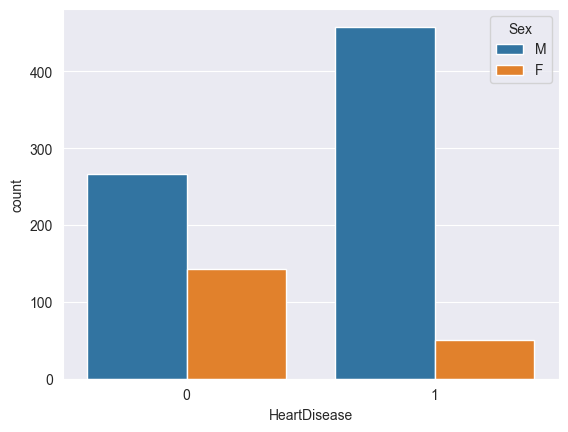

In [182]:
sns.countplot(data=heart,x='HeartDisease',hue = 'Sex')

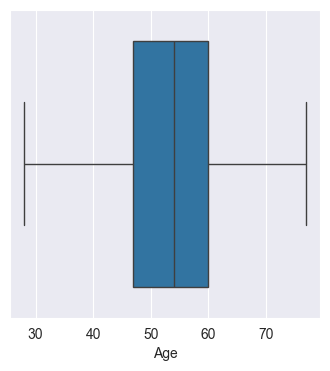

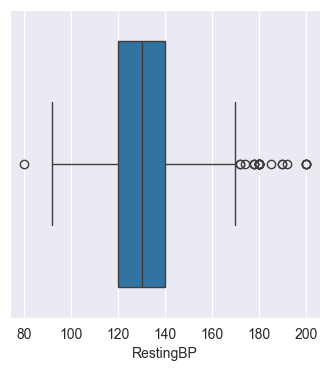

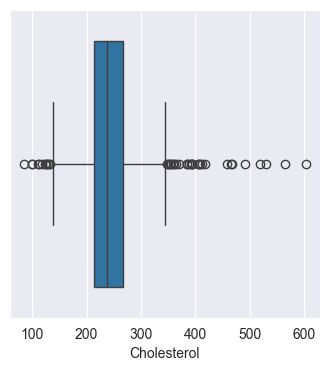

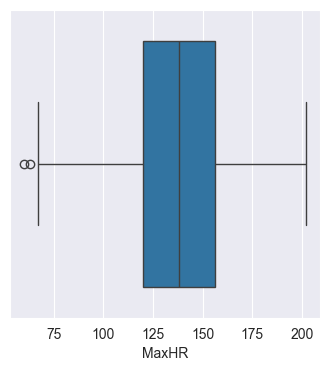

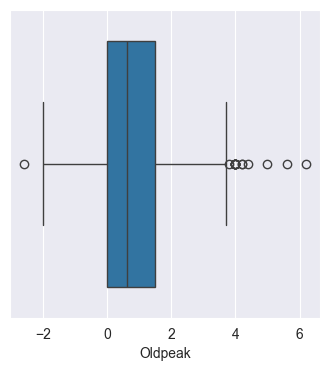

In [183]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
for col in num_cols:
    plt.figure(figsize = (4,4))
    sns.boxplot(data=heart_df,x=col)

In [203]:
heart_df['Sex'] = heart['Sex']
heart_df['ExerciseAngina'] = heart['ExerciseAngina']
heart_df['Sex'] = heart_df['Sex'].map({'F':1,'M':0})
heart_df['ExerciseAngina'] = heart_df['ExerciseAngina'].map({'Y':1,'N':0})
heart_df

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,is_Female,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,Sex,ExerciseAngina
0,-1.433140,0.415002,0.858035,0,1.382928,-0.832432,0,1,0,0,1,0,1,0,0,0,0
1,-0.478484,1.527329,-1.184227,0,0.754157,0.105664,1,1,0,1,0,1,0,1,0,1,0
2,-1.751359,-0.141161,0.745617,0,-1.525138,-0.832432,0,0,1,0,1,0,1,0,0,0,0
3,-0.584556,0.303769,-0.547191,0,-1.132156,0.574711,1,1,0,1,0,1,0,0,0,1,1
4,0.051881,0.971166,-0.903182,0,-0.581981,-0.832432,0,1,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.253488,0.389626,0,-0.188999,0.293283,1,1,0,1,0,0,0,0,1,0,0
914,1.536902,0.637468,-0.940654,1,0.164684,2.357094,1,1,0,1,0,0,0,0,0,0,0
915,0.370100,-0.141161,-2.102308,0,-0.857069,0.293283,1,1,0,1,0,0,0,0,0,0,1
916,0.370100,-0.141161,-0.134991,0,1.461525,-0.832432,1,0,0,1,0,1,1,0,0,1,0


In [185]:
heart_df.columns.tolist()

['Age',
 'Sex',
 'ChestPainType',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'RestingECG',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'ST_Slope',
 'HeartDisease']

In [186]:
heart_df = heart_df.drop(columns=['ExerciseAngina'])
heart_df = heart_df.drop(columns=['Sex'])

In [202]:
heart_df.rename(columns={'Sex':'is_Female',
                  'ExerciseAngina':'is_ExerciseAngina'},inplace=True)

In [188]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Age            918 non-null    int64  
 1   ChestPainType  918 non-null    object 
 2   RestingBP      918 non-null    float64
 3   Cholesterol    918 non-null    float64
 4   FastingBS      918 non-null    int64  
 5   RestingECG     918 non-null    object 
 6   MaxHR          918 non-null    int64  
 7   Oldpeak        918 non-null    float64
 8   ST_Slope       918 non-null    object 
 9   HeartDisease   918 non-null    int64  
dtypes: float64(3), int64(4), object(3)
memory usage: 71.8+ KB


In [189]:
print(heart_df.columns.tolist())
print(heart_df.isna().sum())

['Age', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'Oldpeak', 'ST_Slope', 'HeartDisease']
Age              0
ChestPainType    0
RestingBP        0
Cholesterol      0
FastingBS        0
RestingECG       0
MaxHR            0
Oldpeak          0
ST_Slope         0
HeartDisease     0
dtype: int64


In [193]:
heart_df = pd.get_dummies(heart_df,columns=['RestingECG'],drop_first=True,dtype = int)

KeyError: "None of [Index(['RestingECG'], dtype='object')] are in the [columns]"

In [194]:
heart_df = pd.get_dummies(heart_df,columns=['ST_Slope'],drop_first=True,dtype = int)

KeyError: "None of [Index(['ST_Slope'], dtype='object')] are in the [columns]"

In [198]:
heart_df = pd.get_dummies(heart_df,columns=['ChestPainType'],drop_first=True,dtype = int)


In [196]:
columns = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']
Scaler = StandardScaler()
heart_df[columns] = Scaler.fit_transform(heart_df[columns])

In [160]:
print(type(heart_df))

<class 'numpy.ndarray'>


In [163]:
heart_df = pd.DataFrame(heart_df)

In [164]:
heart_df

,0,1,2,3,4
0,-1.433140,0.415002,0.858035,1.382928,-0.727592
1,-0.478484,1.527329,-1.184227,0.754157,0.282891
2,-1.751359,-0.141161,0.745617,-1.525138,-0.727592
3,-0.584556,0.303769,-0.547191,-1.132156,0.282891
4,0.051881,0.971166,-0.903182,-0.581981,-0.727592
...,...,...,...,...,...
913,-0.902775,-1.253488,0.389626,-0.188999,0.282891
914,1.536902,0.637468,-0.940654,0.164684,2.303858
915,0.370100,-0.141161,-2.102308,-0.857069,0.282891
916,0.370100,-0.141161,-0.134991,1.461525,-0.727592


In [166]:
print(type(heart))
print(heart.shape)
print(heart.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
(918, 12)
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [204]:
heart_df = heart_df.drop(columns=['Sex'])

In [206]:
heart_df.rename(columns={'ExerciseAngina':'is_ExerciseAngina'},inplace=True)

In [207]:
heart_df

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,is_Female,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,is_ExerciseAngina
0,-1.433140,0.415002,0.858035,0,1.382928,-0.832432,0,1,0,0,1,0,1,0,0,0
1,-0.478484,1.527329,-1.184227,0,0.754157,0.105664,1,1,0,1,0,1,0,1,0,0
2,-1.751359,-0.141161,0.745617,0,-1.525138,-0.832432,0,0,1,0,1,0,1,0,0,0
3,-0.584556,0.303769,-0.547191,0,-1.132156,0.574711,1,1,0,1,0,1,0,0,0,1
4,0.051881,0.971166,-0.903182,0,-0.581981,-0.832432,0,1,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.253488,0.389626,0,-0.188999,0.293283,1,1,0,1,0,0,0,0,1,0
914,1.536902,0.637468,-0.940654,1,0.164684,2.357094,1,1,0,1,0,0,0,0,0,0
915,0.370100,-0.141161,-2.102308,0,-0.857069,0.293283,1,1,0,1,0,0,0,0,0,1
916,0.370100,-0.141161,-0.134991,0,1.461525,-0.832432,1,0,0,1,0,1,1,0,0,0


In [209]:
heart_df.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat',
       'ST_Slope_Up', 'is_Female', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'is_ExerciseAngina'],
      dtype='object')

In [213]:
selected_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak'
       , 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat',
       'ST_Slope_Up', 'is_Female', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'is_ExerciseAngina']
Correlation = {feature : pearsonr(heart_df[feature], heart_df['HeartDisease'])[0]
               for feature in selected_features
               }
corr_df = pd.DataFrame(list(Correlation.items()), columns=['Feature', 'Value'])
corr_df.sort_values(by='Value', ascending=False, inplace=True)
print(corr_df)


              Feature     Value
8       ST_Slope_Flat  0.554134
14  is_ExerciseAngina  0.494282
5             Oldpeak  0.403951
0                 Age  0.282039
3           FastingBS  0.267291
1           RestingBP  0.117798
7       RestingECG_ST  0.102527
2         Cholesterol  0.076114
13   ChestPainType_TA -0.054790
6   RestingECG_Normal -0.091580
12  ChestPainType_NAP -0.212964
10          is_Female -0.305445
4               MaxHR -0.400421
11  ChestPainType_ATA -0.401924
9         ST_Slope_Up -0.622164


In [215]:
cat_features = ['FastingBS','RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat',
       'ST_Slope_Up', 'is_Female', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'is_ExerciseAngina']

In [218]:
alpha = 0.05
chi2_result = {}

for col in cat_features:
    contingency = pd.crosstab(heart_df[col],heart_df['HeartDisease'])
    chi_stat2,p_value,_,_ = chi2_contingency(contingency)
    decision = 'Accept NUll(Drop Feature)' if p_value > alpha else 'Reject NULL(Keep Feature)'
    chi2_result[col] = {
        'chi2_statistics':chi_stat2,
        'p_value':p_value,
        'decision':decision
    }
chi2_df = pd.DataFrame(chi2_result).T
chi2_df.sort_values(by='p_value', ascending=False, inplace=True)
print(chi2_df)

                  chi2_statistics   p_value                   decision
ChestPainType_TA         2.273802  0.131577  Accept NUll(Drop Feature)
RestingECG_Normal        7.327532  0.006791  Reject NULL(Keep Feature)
RestingECG_ST            9.135266  0.002507  Reject NULL(Keep Feature)
ChestPainType_NAP       40.608711       0.0  Reject NULL(Keep Feature)
FastingBS               64.320679       0.0  Reject NULL(Keep Feature)
is_Female               84.145101       0.0  Reject NULL(Keep Feature)
ChestPainType_ATA      146.236323       0.0  Reject NULL(Keep Feature)
is_ExerciseAngina      222.259383       0.0  Reject NULL(Keep Feature)
ST_Slope_Flat          279.659914       0.0  Reject NULL(Keep Feature)
ST_Slope_Up            352.823905       0.0  Reject NULL(Keep Feature)


In [225]:
final_df = heart_df[['Age', 'RestingBP', 'Cholesterol','FastingBS','MaxHR', 'Oldpeak','RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat',
       'ST_Slope_Up', 'is_Female', 'ChestPainType_ATA', 'ChestPainType_NAP', 'is_ExerciseAngina','HeartDisease']]
final_df.shape

(918, 15)